# Hyperpolarized pyruvate–lactate exchange: full-field reconstruction review


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `rat_hyperpolarized_pyruvate_lactate_exchange` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：signal (1, 2, 32, 32, 25) float32：Signed native MR amplitude, arbitrary signal units; axes batch, metabolite (pyruvate, lactate), native x, native y, time.；flip_angles (1, 2, 25) float16：Excitation angles in radians, axes batch, metabolite (pyruvate, lactate), time; author conversion of uint8 nominal degrees is preserved.。恢复目标：32x32 exchange rate s^-1与initial lactate magnetization。

获取模型：两pool ODE通过pyruvate转lactate；RF sin读出/cos耗竭，measured substrate约束每段forcing。实际恢复算法：solvers.reconstruct逐像素有界least_squares；physics_model.trajectory计算matrix exponential。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:7没有独立参数truth，baseline为conditional kinetic估计。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：rat_hyperpolarized_pyruvate_lactate_exchange.ipynb单元3有保存图；图内容由该单元调用的本地visualization函数生成；rat_hyperpolarized_pyruvate_lactate_exchange.ipynb单元5有保存图；ax[1].plot(times,state[1],label='fresh matrix exponential');ax[1].plot(times,analytic,'o',ms=3,label='independent analytic ODE');ax[1].set(xlabel='time (s)',ylabel='longitudinal L ；rat_hyperpolarized_pyruvate_lactate_exchange.ipynb单元7有保存图；图内容由该单元调用的本地visualization函数生成；rat_hyperpolarized_pyruvate_lactate_exchange.ipynb单元8：5. Results and actual experiments；rat_hyperpolarized_pyruvate_lactate_exchange.ipynb单元9有保存图；ax[0].hist(k.ravel(),bins=40,color='#287d8e');ax[0].set(xlabel='conversion rate (s^-1)',ylabel='pixels',title='All1024 rates')；ax[1].hist(l0.ravel(),bins=40,color='#7a68a6');ax[1].；rat_hyperpolarized_pyruvate_lactate_exchange.ipynb单元10有保存图；ax[1,1].hist(res.ravel(),bins=100,color='#527a8a');ax[1,1].set(xlabel='predicted minus measured (a.u.)',ylabel='samples',title='Full signed residual distribution')；rat_hyperpolarized_pyruvate_lactate_exchange.ipynb单元12有保存图；x,z=15,17;ax[1].plot(times,y[x,z],'o',label='observed');ax[1].plot(times,old['Sfit'][x,z,0],label='source boundary start');ax[1].plot(times,pred[x,z],label='fresh interior start');；rat_hyperpolarized_pyruvate_lactate_exchange.ipynb单元13：Identifiability and weak-input sensitivity；rat_hyperpolarized_pyruvate_lactate_exchange.ipynb单元14有保存图；ax[2].bar(np.arange(4)+1,sensitivity_medians,color='#637e9c');ax[2].set(xlabel='Measured-pyruvate peak quartile',ylabel='median diagnostic scale (s^-1)',title='Weak input gives poo；rat_hyperpolarized_pyruvate_lactate_exchange.ipynb单元16有保存图；ax[row,2].scatter(k.ravel(),sf['exchange_rate'].ravel(),s=5,alpha=.45);limit=max(k.max(),sf['excha。图/比较代码位于单元3, 5, 7, 9, 10, 12, 14, 16, 18（从0计数）。代码单元10个，带execution_count的10个，保存PNG输出13幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：本次为静态语义与证据核查，未重新验证数值正确性或运行结果。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

We estimate two spatial fields from **real author-provided rat-kidney images**, retaining the complete native32×32 field and all25 paired time samples. Hyperpolarization decays, RF pulses consume magnetization, and pyruvate is delivered while conversion occurs. The unknowns are nonnegative conversion rate $k$ (s$^{-1}$) and initial longitudinal lactate $L_0$ (native amplitude). Neither has independent measured truth in this dataset. Fresh agreement with an original-method result is numerical validation, not biological validation.

The selected 2018 inputless method uses measured pyruvate as a forcing constraint and fits lactate. We use the author Python API's fixed $T_{1P}=30$ s and $T_{1L}=25$ s, fix the identically unused initial-pyruvate parameter, and impose nonnegative unknowns. A uniform interior initial $L_0=1$ prevents documented boundary-start stalls. This is a declared source API configuration, not an unchanged reproduction of its unconstrained defaults.

The clinical paper's17 patient acquisitions, bolus-fitting comparison, and simulation truths are not this rat dataset. We preserve the relevant scientific logic through measured-data fits, AUC/timing comparisons and actual relaxation/excitation sensitivity refits. We do not invent missing clinical comparison outputs.

In [1]:
import os,sys,time,json,hashlib,subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm
ROOT=Path.cwd()
if not (ROOT/'src').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,prepare
from src.physics_model import rf_factors,trajectory
from src.solvers import reconstruct
from src.visualization import image,compare,relative_l2
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':11,'savefig.facecolor':'white'})
FIG=Path(os.environ['IMAGING_FIGURE_DIR']);FIG.mkdir(parents=True,exist_ok=True)
exports=[]
def publish(fig,name,caption,**arrays):
    fig.suptitle(caption,fontsize=13);fig.tight_layout(rect=(0,0,1,.95))
    for ext in ('png','svg','pdf'):fig.savefig(FIG/(name+'.'+ext),dpi=160,bbox_inches='tight')
    np.savez_compressed(FIG/(name+'.npz'),**arrays)
    meta={'name':name,'caption':caption,'arrays':{k:{'shape':list(np.asarray(v).shape),'dtype':str(np.asarray(v).dtype)} for k,v in arrays.items()},'role':'Computed fresh local data unless explicitly labelled source/reference or independent source diagnostic','files':{ext:{'path':name+'.'+ext,'sha256':hashlib.sha256((FIG/(name+'.'+ext)).read_bytes()).hexdigest()} for ext in ('png','svg','pdf','npz')}}
    (FIG/(name+'.json')).write_text(json.dumps(meta,indent=2),encoding='utf8');exports.append(meta);plt.show();plt.close(fig)
signal,angles=load_data(ROOT/'data/raw_data.npz');times=np.arange(25)*2.;native=np.load(ROOT/'notebooks/reference_outputs/upstream_full.npz',allow_pickle=False);profile=np.load(ROOT/'notebooks/reference_outputs/independent_profile.npz',allow_pickle=False)
print('Bound observations:',signal.shape,signal.dtype,'signed-negative samples',np.count_nonzero(signal<0),'angles',angles.dtype,float(angles[0,0]),'radians')
print('Original source outputs are identified separately from every fresh fit below.')

Bound observations: (2, 32, 32, 25) float32 signed-negative samples 7997 angles float16 0.26171875 radians
Original source outputs are identified separately from every fresh fit below.


## 2. Data

These are the toolbox's `exp2_constant` in-vivo images, already reconstructed from MR acquisition. There is no spatial resampling or output-selected support. Sampling is3mm×3mm over96mm×96mm,20mm thick,25 frames at2s. The related acquisition paper uses3T and explains symmetric EPI and independent reference-scan ghost correction; its zero-filled128² presentation is not a native acquisition grid. The author sample has constant nominal15° excitation for both metabolites. The original uint8-to-radian conversion yields **float16 0.26171875rad**, then the original function's zero-padding promotes to float64 before trig. We preserve that numerical calibration chain.

Signed real data are retained. A fixed per-pixel noise calibration is unavailable; the temporal-difference scale later shown is explicitly a diagnostic. The software is BSD-3-Clause; the offered demonstration has no separate explicit data redistribution licence, which limits public release. It is used here within authorized local research.

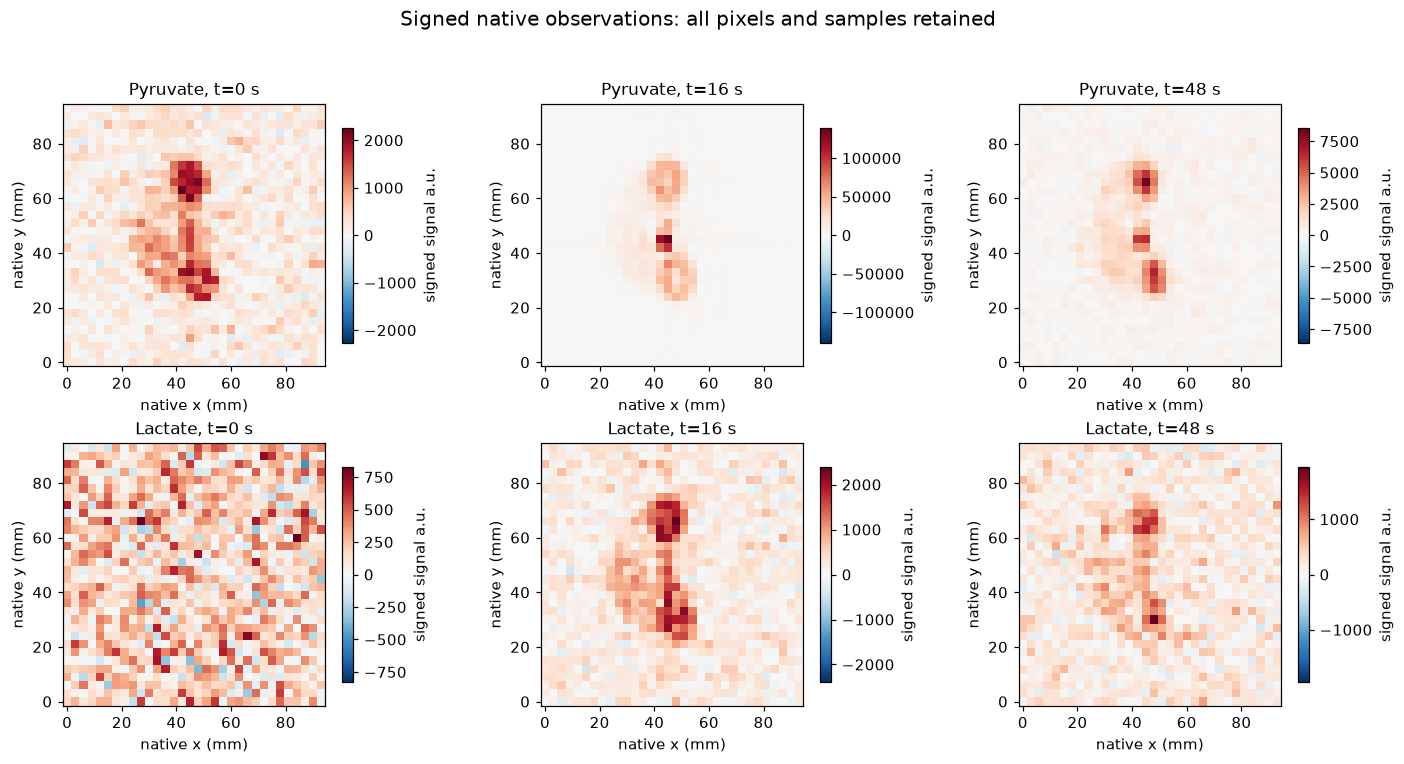

In [2]:
fig,ax=plt.subplots(2,3,figsize=(13,7))
for met,label in enumerate(('Pyruvate','Lactate')):
    for j,t in enumerate((0,8,24)):image(ax[met,j],signal[met,:,:,t],f'{label}, t={times[t]:.0f} s','signed signal a.u.',signed=True)
publish(fig,'01_observed_images','Signed native observations: all pixels and samples retained',signal=signal,times=times,flip_angles=angles)

## 3. Physics

Let pre-RF state $mathbf m=(P,L,B,A)^T$, with only pyruvate and lactate active. The latter two dummy channels remain zero and retain the source4×4 propagator. With $r_P=1/30$ s$^{-1}$, $r_L=1/25$ s$^{-1}$ and interval $h=2$ s,

$$\frac{d\mathbf m}{dt}=\mathbf A\mathbf m+\mathbf b,\qquad
\mathbf A=\begin{pmatrix}-r_P-k&0&0&0\\k&-r_L&0&0\\0&0&-1&0\\0&0&0&-1\end{pmatrix},\quad \mathbf b=(u,0,0,0)^T.$$

Measured signal is $s_X[n]=S_X[n]X[n]$, $S_X=\sin\theta_X$; post-RF state is $Z_X X$, $Z_X=\cos\theta_X$. Eliminate the constant interval forcing using observed adjacent pyruvate endpoints:

$$u_n=\frac{[P_{n+1}-Z_{Pn}P_n\exp(-(r_P+k)h)](r_P+k)}{1-\exp(-(r_P+k)h)},\quad
\mathbf x_*=-\mathbf A^{-1}\mathbf b,$$
$$\mathbf m_{n+1}=\mathbf x_*+\exp(\mathbf A h)(\mathbf Z_n\odot\mathbf m_n-\mathbf x_*).$$

All symbols refer to native longitudinal arbitrary amplitude, seconds, or inverse seconds. The minus sign in the equilibrium follows directly from $\mathbf A\mathbf x_*+\mathbf b=0$ and is checked by an independent constant-substrate solution. The source code uses it; extracted PDF text alone is not treated as proof of a paper-sign error. Forcing may be negative because noisy signed pyruvate is imposed, not a true independently measured nonnegative vascular input.

The source initial-pyruvate parameter has **zero forward effect**: all pyruvate states are overwritten by observations. We fix it through the original API rather than score an unidentifiable field. The two remaining fields stay complete.

Independent constant-substrate error 4.440892098500626e-16 RF depletion error 6.661338147750939e-16


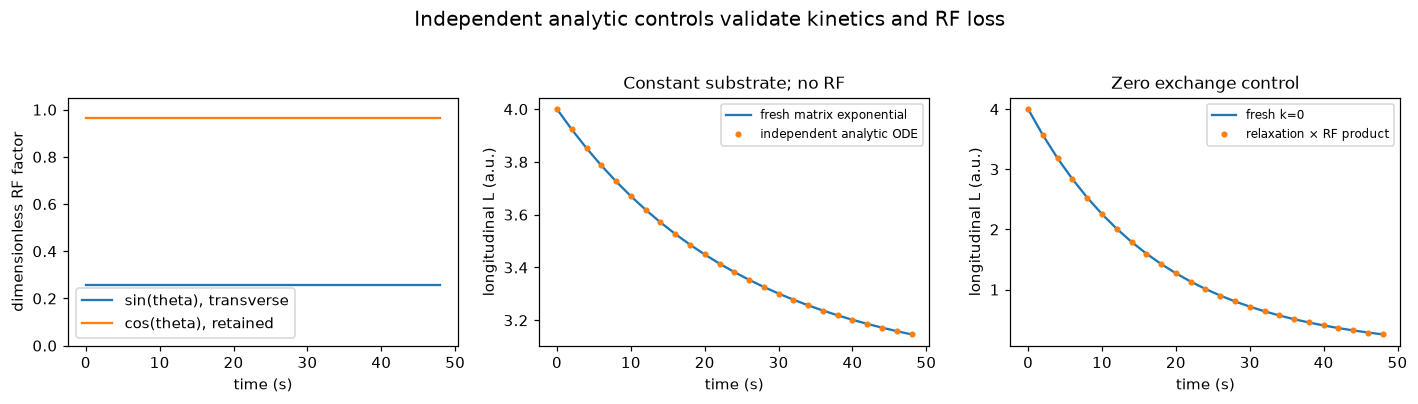

In [3]:
padded,flips=prepare(signal,angles);ss,zz=rf_factors(flips)
fixture=np.load(ROOT/'test/fixtures/upstream_stages.npz',allow_pickle=False)
fig,ax=plt.subplots(1,3,figsize=(13,3.7))
ax[0].plot(times,ss[0],label='sin(theta), transverse');ax[0].plot(times,zz[0],label='cos(theta), retained');ax[0].set(xlabel='time (s)',ylabel='dimensionless RF factor',ylim=(0,1.05));ax[0].legend()
p=np.full(25,10.);state,u=trajectory([.012,4.],p,np.ones((4,25)));analytic=4*np.exp(-times/25)+.012*10*25*(1-np.exp(-times/25))
ax[1].plot(times,state[1],label='fresh matrix exponential');ax[1].plot(times,analytic,'o',ms=3,label='independent analytic ODE');ax[1].set(xlabel='time (s)',ylabel='longitudinal L (a.u.)',title='Constant substrate; no RF');ax[1].legend(fontsize=8)
state0,_=trajectory([0,4.],p,zz);exact0=4*(zz[1,0]*np.exp(-2/25))**np.arange(25)
ax[2].plot(times,state0[1],label='fresh k=0');ax[2].plot(times,exact0,'o',ms=3,label='relaxation × RF product');ax[2].set(xlabel='time (s)',ylabel='longitudinal L (a.u.)',title='Zero exchange control');ax[2].legend(fontsize=8)
print('Independent constant-substrate error',np.max(abs(state[1]-analytic)),'RF depletion error',np.max(abs(state0[1]-exact0)))
publish(fig,'02_rf_and_known_physics','Independent analytic controls validate kinetics and RF loss',times=times,transverse=ss,longitudinal=zz,constant_substrate_fresh=state,constant_substrate_exact=analytic,zero_exchange_fresh=state0,zero_exchange_exact=exact0)

## 4. Method

At each pixel, minimize half the sum of squared **transverse lactate** residuals, with no spatial smoothing or noise weights:

$$F(k,L_0)=\frac12\sum_{n=0}^{24}[(M^{\rm obs}_{Ln}-M^{\rm model}_{Ln})S_{Ln}]^2,\qquad k\ge0,\ L_0\ge0.$$

The selected source API uses SciPy TRF, two-point finite differences, tolerances$10^{-6}$ and initial$(0.002,1)$. The interior initial lactate produces only about0.259 signal unit and does not encode a target field. Fixed relaxation is a conditional assumption, not a measured calibration. Matrix inverse/exponential are computed once per trajectory and reused across identical time intervals. Scalar indexing adapts NumPy's changed array-to-scalar rule without a changed equation.

The following cell **actively reconstructs all1024 pixels** from raw observations with local explicit mathematics. No cached reconstruction is substituted. Historical original arrays are used only for identified comparisons.

Fresh complete reconstruction seconds: 28.823038399976213
{
  "exchange_rate": {
    "ncc": 0.9999999999999819,
    "dr_nrmse": 4.573957748950697e-08,
    "max_abs_over_range": 8.201226081877829e-07
  },
  "initial_lactate": {
    "ncc": 0.9999999999999076,
    "dr_nrmse": 7.139788926671538e-08,
    "max_abs_over_range": 1.6910595211765337e-06
  }
}
Native source objective total: 580067796.526546 fresh: 580067796.5265384


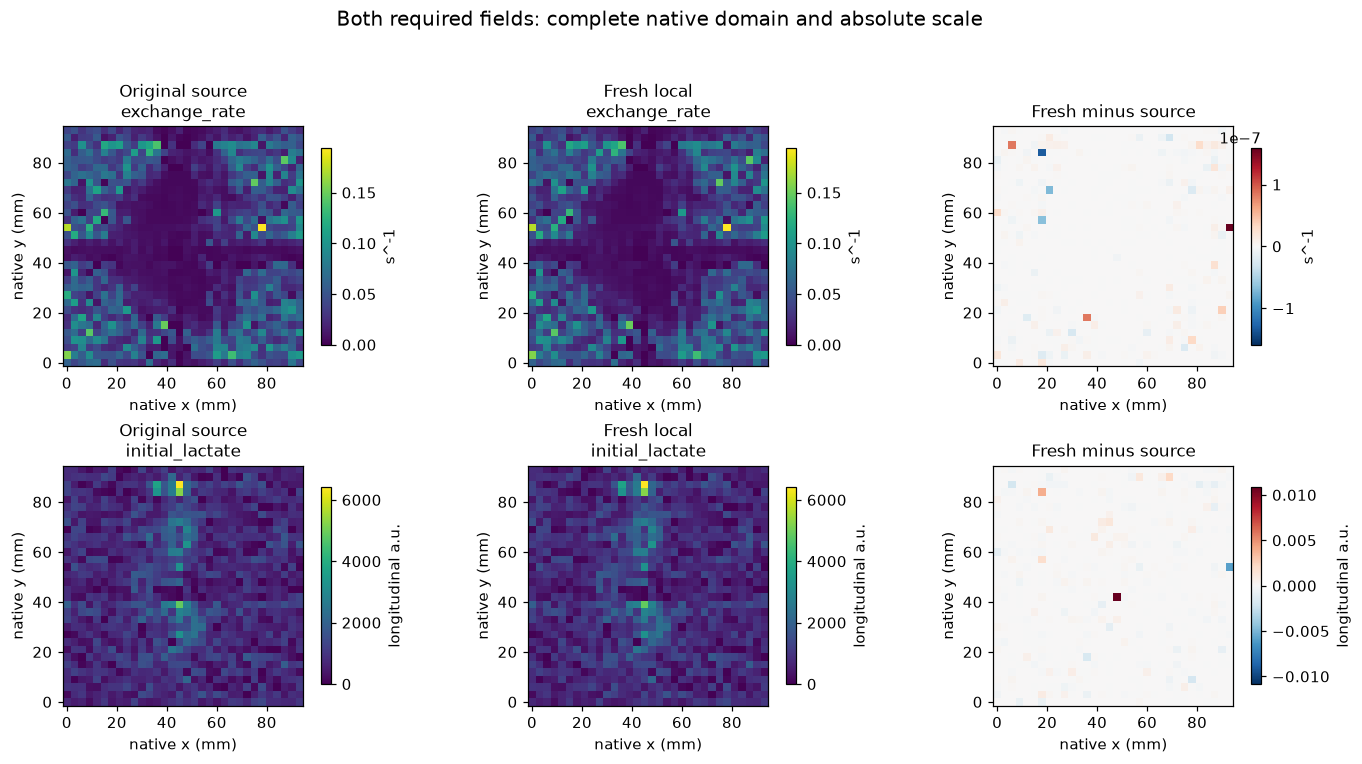

In [4]:
start=time.perf_counter();fresh,diagnostics=reconstruct(signal,angles);reconstruction_seconds=time.perf_counter()-start
np.savez_compressed(ROOT/'output/reconstruction.npz',**fresh)
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_full.npz',**fresh,**diagnostics)
reference={'exchange_rate':native['params_fit'][:,0].reshape(1,32,32),'initial_lactate':native['params_fit'][:,1].reshape(1,32,32)}
agreement={k:compare(fresh[k],reference[k]) for k in fresh}
print('Fresh complete reconstruction seconds:',reconstruction_seconds);print(json.dumps(agreement,indent=2));print('Native source objective total:',float(native['objective'].sum()),'fresh:',float(diagnostics['objective'].sum()))
fig,ax=plt.subplots(2,3,figsize=(13,7))
for row,(k,unit) in enumerate((('exchange_rate','s^-1'),('initial_lactate','longitudinal a.u.'))):
    image(ax[row,0],reference[k][0],'Original source\n'+k,unit);image(ax[row,1],fresh[k][0],'Fresh local\n'+k,unit);image(ax[row,2],(fresh[k]-reference[k])[0],'Fresh minus source',unit,signed=True)
publish(fig,'03_fields_source_fresh','Both required fields: complete native domain and absolute scale',source_k=reference['exchange_rate'],fresh_k=fresh['exchange_rate'],source_L0=reference['initial_lactate'],fresh_L0=fresh['initial_lactate'])

## 5. Results and actual experiments

We separate numerical reproduction, observation fit, physical identifiability and assumed-calibration sensitivity. A good source/local agreement does not establish an absolute biochemical rate, especially in noise-dominated pixels. Every experiment below retains the full field.

### Full-field distributions and time courses

The source uses signed images, so a model with nonnegative parameters may still predict a negative lactate sample through a negative inferred interval forcing. We display/count that outcome instead of clipping it. Spatial maps use native axes and3mm sampling; there is no image registration or amplitude normalization.

Negative fitted lactate samples: 21 minimum -67.30586124541081 negative forcing samples 11161


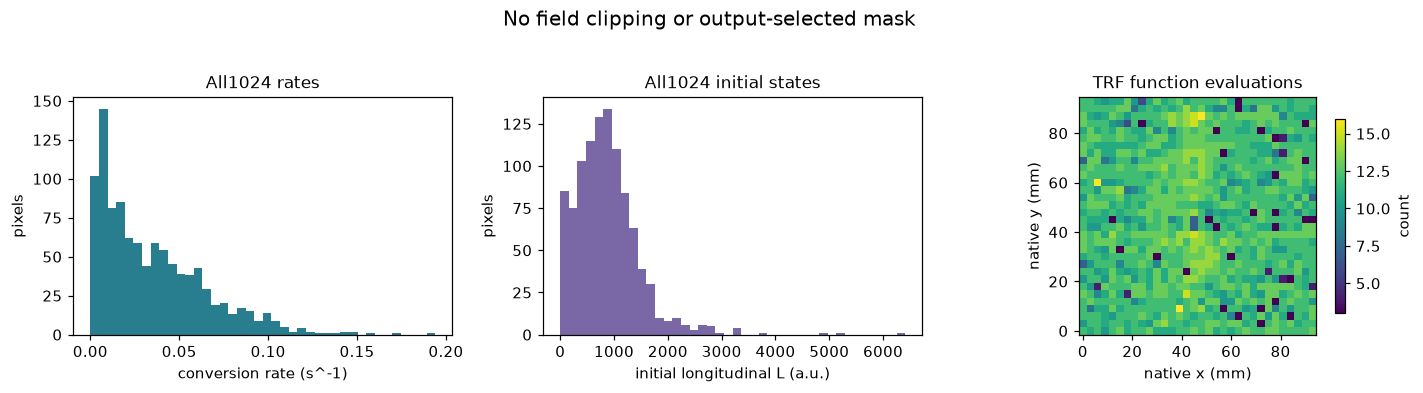

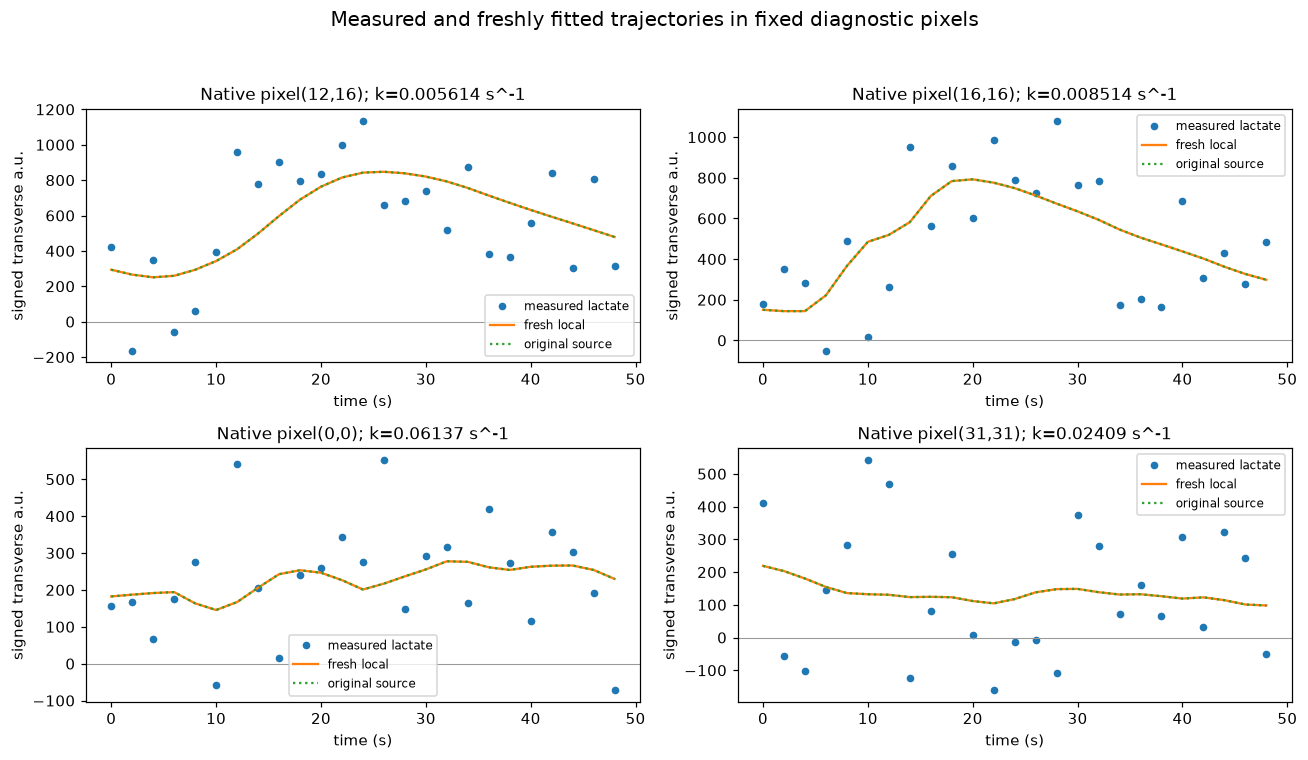

In [5]:
k=fresh['exchange_rate'][0];l0=fresh['initial_lactate'][0];pred=diagnostics['fitted_lactate'];y=signal[1];res=pred-y
fig,ax=plt.subplots(1,3,figsize=(13,3.6))
ax[0].hist(k.ravel(),bins=40,color='#287d8e');ax[0].set(xlabel='conversion rate (s^-1)',ylabel='pixels',title='All1024 rates')
ax[1].hist(l0.ravel(),bins=40,color='#7a68a6');ax[1].set(xlabel='initial longitudinal L (a.u.)',ylabel='pixels',title='All1024 initial states')
image(ax[2],diagnostics['nfev'],'TRF function evaluations','count')
print('Negative fitted lactate samples:',np.count_nonzero(pred<0),'minimum',pred.min(),'negative forcing samples',np.count_nonzero(diagnostics['forcing_signal_scaled']<0))
publish(fig,'04_parameter_distributions','No field clipping or output-selected mask',k=k,L0=l0,nfev=diagnostics['nfev'],status=diagnostics['status'])
coords=[(12,16),(16,16),(0,0),(31,31)]
fig,ax=plt.subplots(2,2,figsize=(12,7))
for a,(x,z) in zip(ax.flat,coords):
    a.plot(times,y[x,z],'o',ms=4,label='measured lactate');a.plot(times,pred[x,z],label='fresh local');a.plot(times,native['Sfit'][x,z,0],':',label='original source');a.axhline(0,color='.6',lw=.7)
    a.set(xlabel='time (s)',ylabel='signed transverse a.u.',title=f'Native pixel({x},{z}); k={k[x,z]:.4g} s^-1');a.legend(fontsize=8)
publish(fig,'05_temporal_fits','Measured and freshly fitted trajectories in fixed diagnostic pixels',times=times,coordinates=np.array(coords),measured=y,predicted=pred,source=native['Sfit'][:,:,0,:])

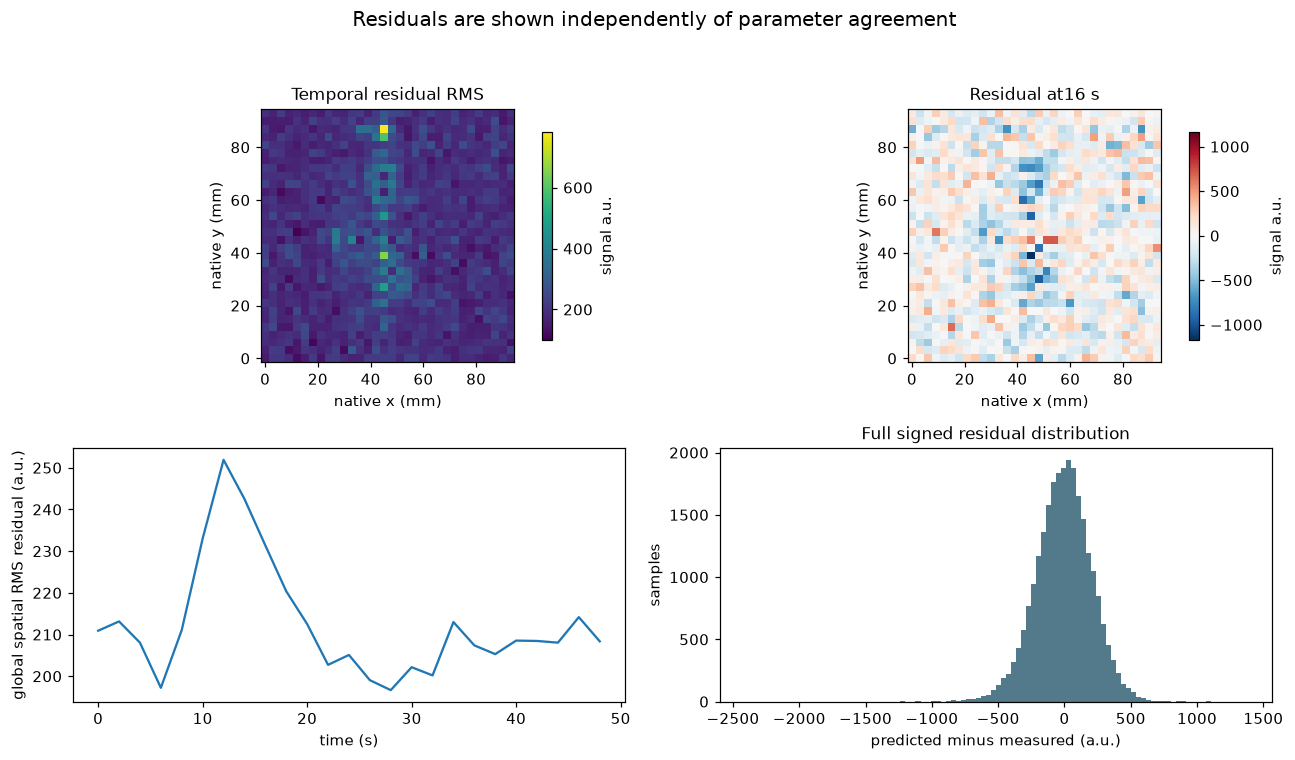

Global observation L2 null comparison: {'Zero signal': 1.0, 'Per-pixel constant': 0.5660148859024048, 'k=0, fitted L0': 0.8332749565668754, 'Fresh inputless': 0.489943916066924}


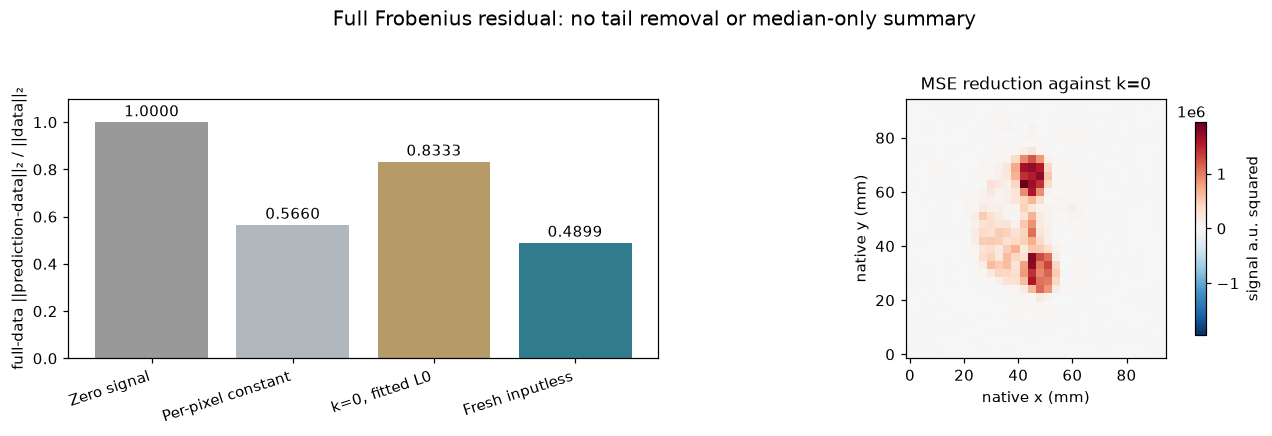

In [6]:
fig,ax=plt.subplots(2,2,figsize=(12,7))
image(ax[0,0],np.sqrt(np.mean(res**2,axis=-1)),'Temporal residual RMS','signal a.u.');image(ax[0,1],res[:,:,8],'Residual at16 s','signal a.u.',signed=True)
ax[1,0].plot(times,np.sqrt(np.mean(res**2,axis=(0,1))));ax[1,0].set(xlabel='time (s)',ylabel='global spatial RMS residual (a.u.)')
ax[1,1].hist(res.ravel(),bins=100,color='#527a8a');ax[1,1].set(xlabel='predicted minus measured (a.u.)',ylabel='samples',title='Full signed residual distribution')
publish(fig,'06_observation_residuals','Residuals are shown independently of parameter agreement',residual=res,times=times,measured=y,predicted=pred)
# Exact optimal L0 under the zero-conversion null: RF and lactate relaxation only.
phi=np.empty(25);phi[0]=ss[1,0]
for t in range(1,25):phi[t]=phi[t-1]*np.exp(-2/25)*zz[1,t-1]*ss[1,t]/ss[1,t-1]
null_l0=np.maximum(y.reshape(-1,25)@phi/np.dot(phi,phi),0).reshape(32,32)
null=phi*null_l0[...,None];constant=np.broadcast_to(y.mean(-1)[...,None],y.shape)
null_labels=['Zero signal','Per-pixel constant','k=0, fitted L0','Fresh inputless']
null_values=[1.,relative_l2(constant,y),relative_l2(null,y),relative_l2(pred,y)]
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].bar(np.arange(4),null_values,color=['#999999','#b0b8bd','#b69b68','#317c8c']);ax[0].set_xticks(np.arange(4),null_labels,rotation=18,ha='right');ax[0].set(ylabel='full-data ||prediction-data||₂ / ||data||₂',ylim=(0,1.1))
for i,v in enumerate(null_values):ax[0].text(i,v+.025,f'{v:.4f}',ha='center')
image(ax[1],np.mean((null-y)**2-(pred-y)**2,axis=-1),'MSE reduction against k=0','signal a.u. squared',signed=True)
print('Global observation L2 null comparison:',dict(zip(null_labels,null_values)))
publish(fig,'07_forward_null_comparison','Full Frobenius residual: no tail removal or median-only summary',metrics=np.array(null_values),zero_conversion_prediction=null,constant_prediction=constant,fresh_prediction=pred,observed=y)

### Source boundary initialization and numerical reproducibility

An earlier **source-only** configuration initialized lactate exactly at its lower bound. Nine pixels had detectable premature termination; one fixed example is shown. A declared uniform interior start eliminates this numerical stall. This diagnostic compares two original API configurations and the fresh extraction, not two biological ground truths. Full original reruns with the selected interior start were bitwise identical. The NumPy2 compatibility run and frozen numerical criteria predate local extraction.

The broad independent source-only profile grid optimized nonnegative $L_0$ analytically at each rate. Its best objective improvement over the selected source solution was below$3\times10^{-10}$ relative per pixel; conditional exact-$L_0$ total improvement was about$2\times10^{-11}$. These profiles are diagnostic checks, not substituted reconstructions.

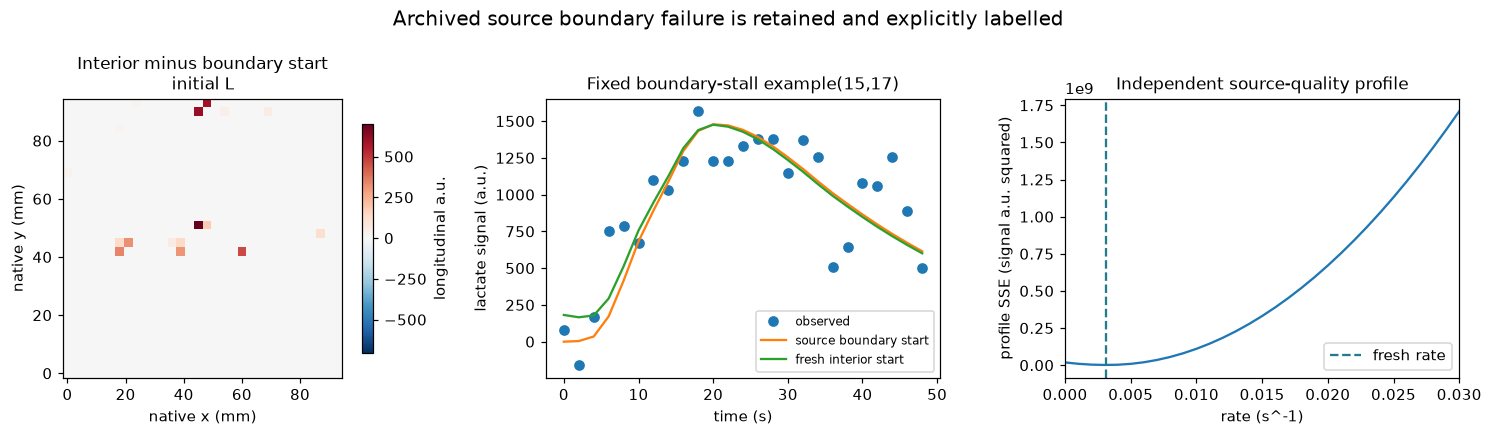

In [7]:
old=np.load(ROOT/'notebooks/reference_outputs/source_boundary_initialization.npz',allow_pickle=False)
fig,ax=plt.subplots(1,3,figsize=(14,4))
image(ax[0],l0-old['params_fit'][:,1].reshape(32,32),'Interior minus boundary start\ninitial L','longitudinal a.u.',signed=True)
x,z=15,17;ax[1].plot(times,y[x,z],'o',label='observed');ax[1].plot(times,old['Sfit'][x,z,0],label='source boundary start');ax[1].plot(times,pred[x,z],label='fresh interior start');ax[1].set(xlabel='time (s)',ylabel='lactate signal (a.u.)',title='Fixed boundary-stall example(15,17)');ax[1].legend(fontsize=8)
idx=x*32+z;rates=profile['rates'];sse=profile['profile_sse'][:,idx];ax[2].plot(rates[rates<=.03],sse[rates<=.03]);ax[2].axvline(k[x,z],color='#237b8b',ls='--',label='fresh rate');ax[2].set(xlim=(0,.03),xlabel='rate (s^-1)',ylabel='profile SSE (signal a.u. squared)',title='Independent source-quality profile');ax[2].legend()
publish(fig,'08_initialization_and_profile','Archived source boundary failure is retained and explicitly labelled',boundary_parameters=old['params_fit'],interior_fresh_k=k,interior_fresh_L0=l0,boundary_fitted=old['Sfit'],profile_rates=rates,profile_sse=profile['profile_sse'],coordinates=np.array([x,z]))

### Identifiability and weak-input sensitivity

There is no exchange information if pyruvate and lactate are identically zero. Nonzero noisy background can give a full-rank numerical Jacobian without proving useful biological recovery. We compute the fresh local25×2 Jacobian at **every** solution. Normalizing its columns separates collinearity from absolute signal information. Projecting the rate derivative off the initial-state derivative gives the conditional local rate sensitivity.

We scale that derivative by temporal-difference MAD/$(0.67449\sqrt2)$ from observed lactate. This is an observed-data **diagnostic scale**, not independent scanner noise or a calibrated confidence interval. The four strata are fixed quartiles of measured pyruvate peak, independent of estimated rates; all four remain scored.

Fresh all-pixel normalized condition range 1.0069201886673118 2.4179172868738585 full rank True
Noise diagnostic 203.50752180422336 quartile sensitivity medians [0.02368832 0.01803159 0.00816704 0.00099747]


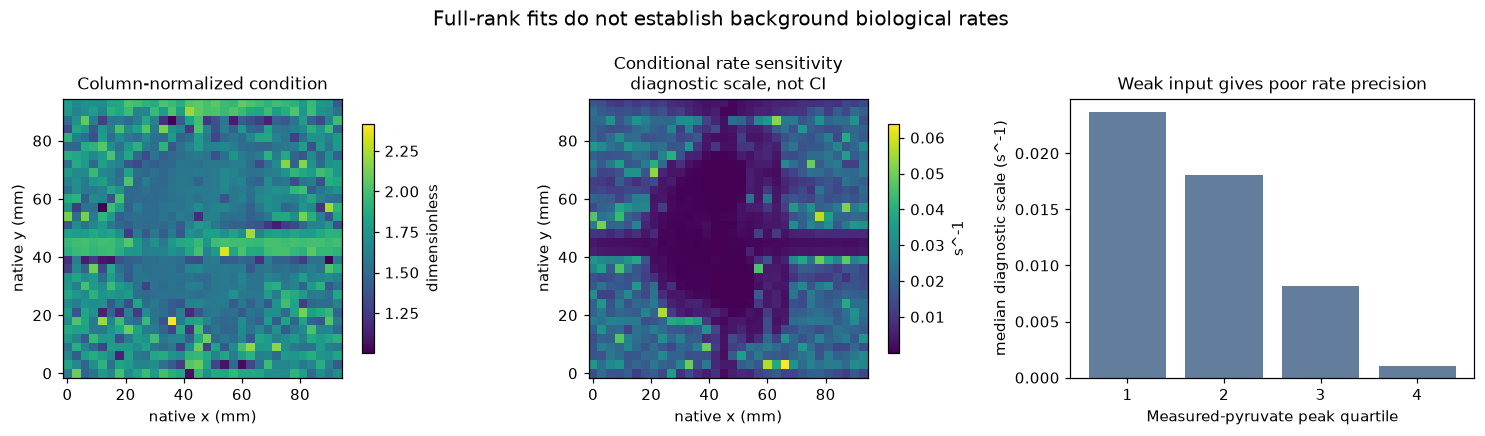

In [8]:
J=np.empty((1024,25,2));par=np.stack([k.ravel(),l0.ravel()],axis=-1)
for i in range(1024):
    for j,step in enumerate((1e-6,.01)):
        plus=par[i].copy();minus=par[i].copy();plus[j]+=step;minus[j]-=step
        a,_=trajectory(plus,padded[i,0]/ss[0],zz);b,_=trajectory(minus,padded[i,0]/ss[0],zz);J[i,:,j]=(a[1]-b[1])*ss[1]/(2*step)
norms=np.linalg.norm(J,axis=1);rho=np.sum(J[:,:,0]*J[:,:,1],axis=1)/np.prod(norms,axis=-1);condition=np.sqrt((1+abs(rho))/(1-abs(rho)))
projected=J[:,:,0]-(np.sum(J[:,:,0]*J[:,:,1],axis=1)/np.sum(J[:,:,1]**2,axis=1))[:,None]*J[:,:,1]
diff=np.diff(y,axis=-1);noise_diagnostic=np.median(abs(diff-np.median(diff)))/(.6744897501960817*np.sqrt(2));sensitivity=noise_diagnostic/np.linalg.norm(projected,axis=1)
peak=signal[0].max(-1).ravel();edges=np.quantile(peak,[0,.25,.5,.75,1]);quartile=np.minimum(np.searchsorted(edges[1:-1],peak,side='right'),3);sensitivity_medians=np.array([np.median(sensitivity[quartile==i]) for i in range(4)])
fig,ax=plt.subplots(1,3,figsize=(14,4))
image(ax[0],condition.reshape(32,32),'Column-normalized condition','dimensionless');image(ax[1],sensitivity.reshape(32,32),'Conditional rate sensitivity\ndiagnostic scale, not CI','s^-1')
ax[2].bar(np.arange(4)+1,sensitivity_medians,color='#637e9c');ax[2].set(xlabel='Measured-pyruvate peak quartile',ylabel='median diagnostic scale (s^-1)',title='Weak input gives poor rate precision')
print('Fresh all-pixel normalized condition range',condition.min(),condition.max(),'full rank',bool(np.all(np.isfinite(condition))));print('Noise diagnostic',noise_diagnostic,'quartile sensitivity medians',sensitivity_medians)
publish(fig,'09_information_and_weak_signal','Full-rank fits do not establish background biological rates',jacobian=J,condition=condition.reshape(32,32),sensitivity_scale=sensitivity.reshape(32,32),quartile=quartile.reshape(32,32),quartile_edges=edges,quartile_medians=sensitivity_medians)

### Actual full-field relaxation and excitation refits

The fixed $T_1$ values are assumptions. We refit all1024 pixels at lactate $T_1=20$ and30s, with every other selected solver convention unchanged. We also refit with both supplied flip-angle arrays multiplied by0.95 and1.05 **after preserving the bound calibration conversion**. These are alternative assumed calibration conditions, not newly generated observations, calibrated B1 measurements, or uncertainty intervals. Comparing all-pixel maps exposes dependence that source parity cannot detect.

T1L20 full1024 seconds 28.562922999990406 observation L2 0.49028974606567355


T1L30 full1024 seconds 28.53327280000667 observation L2 0.49074577300995414


flip095 full1024 seconds 28.698565200000303 observation L2 0.4900727227477291


flip105 full1024 seconds 26.943119400006253 observation L2 0.48986828601704635


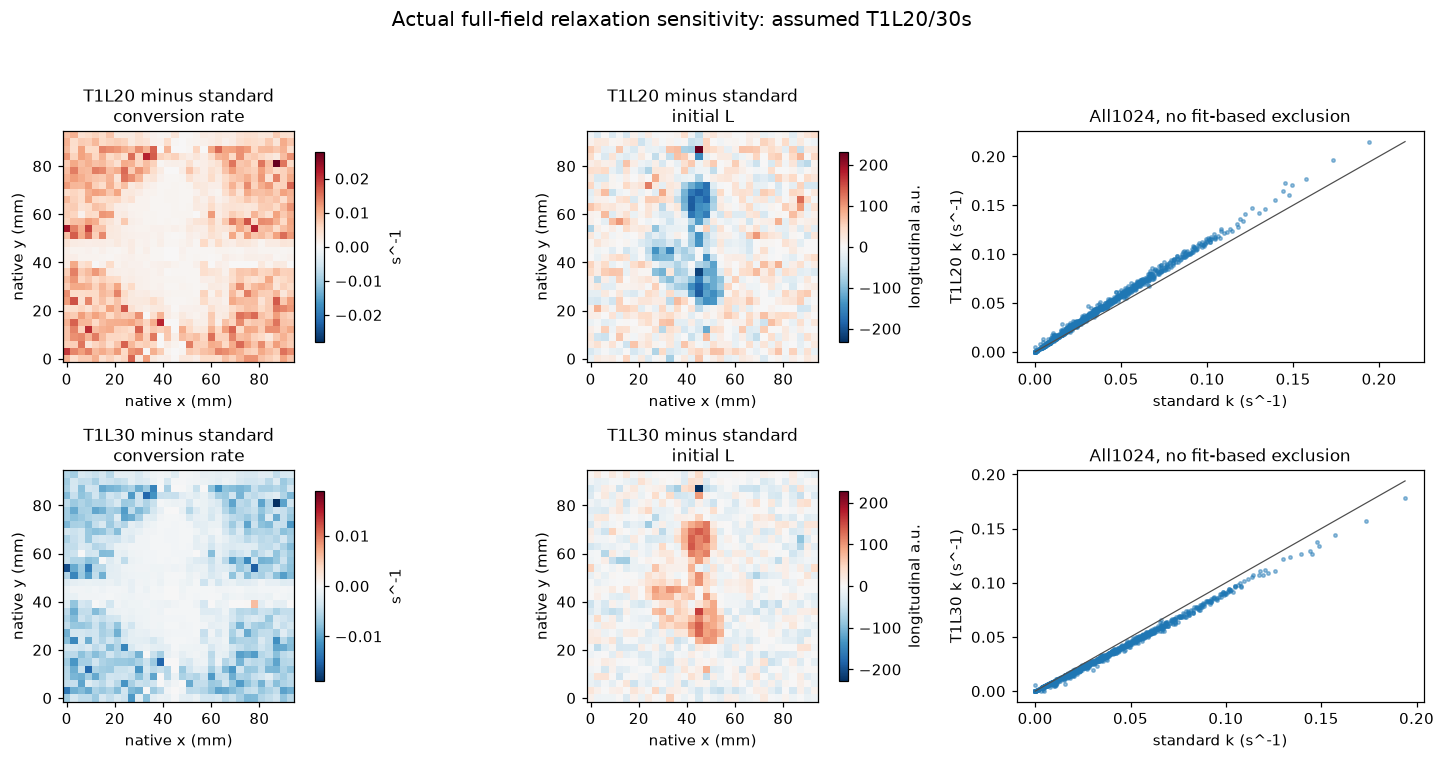

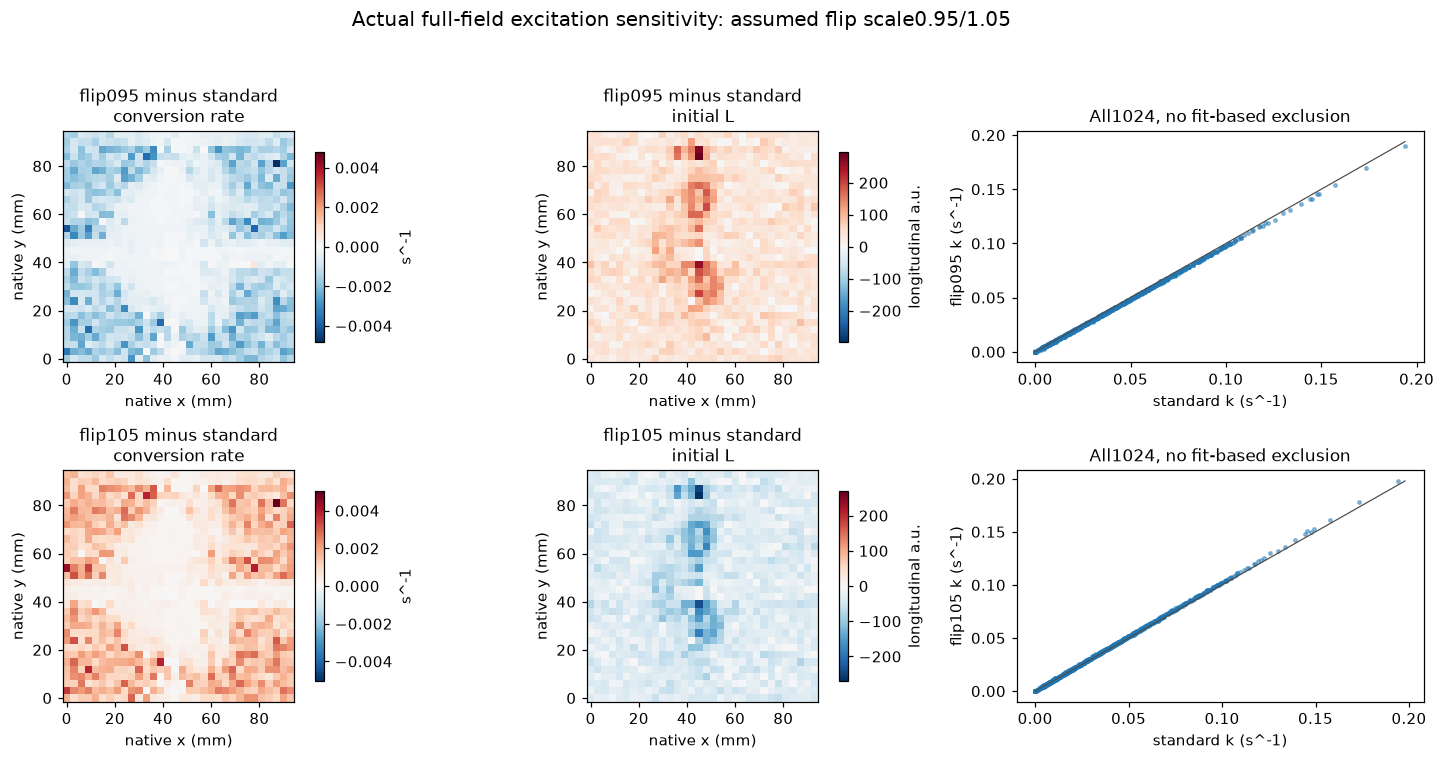

In [9]:
sensitivity_fits={};sensitivity_diagnostics={};sensitivity_times={}
for label,t1l,scale in [('T1L20',20.,1.),('T1L30',30.,1.),('flip095',25.,.95),('flip105',25.,1.05)]:
    start=time.perf_counter();sf,sd=reconstruct(signal,angles.astype(float)*scale,t1l=t1l);sensitivity_times[label]=time.perf_counter()-start;sensitivity_fits[label]=sf;sensitivity_diagnostics[label]=sd
    print(label,'full1024 seconds',sensitivity_times[label],'observation L2',relative_l2(sd['fitted_lactate'],y))
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_sensitivity.npz',**{label+'_'+k:v for label,result in sensitivity_fits.items() for k,v in result.items()},**{label+'_fitted_lactate':v['fitted_lactate'] for label,v in sensitivity_diagnostics.items()})
for number,prefix,labels,caption in [('10','relaxation',('T1L20','T1L30'),'Actual full-field relaxation sensitivity: assumed T1L20/30s'),('11','excitation',('flip095','flip105'),'Actual full-field excitation sensitivity: assumed flip scale0.95/1.05')]:
    fig,ax=plt.subplots(2,3,figsize=(14,7));payload={}
    for row,label in enumerate(labels):
        sf=sensitivity_fits[label];dk=sf['exchange_rate'][0]-k;dl=sf['initial_lactate'][0]-l0
        image(ax[row,0],dk,label+' minus standard\nconversion rate','s^-1',signed=True);image(ax[row,1],dl,label+' minus standard\ninitial L','longitudinal a.u.',signed=True)
        ax[row,2].scatter(k.ravel(),sf['exchange_rate'].ravel(),s=5,alpha=.45);limit=max(k.max(),sf['exchange_rate'].max());ax[row,2].plot([0,limit],[0,limit],color='.3',lw=.8);ax[row,2].set(xlabel='standard k (s^-1)',ylabel=label+' k (s^-1)',title='All1024, no fit-based exclusion')
        payload[label+'_k']=sf['exchange_rate'];payload[label+'_L0']=sf['initial_lactate'];payload[label+'_prediction']=sensitivity_diagnostics[label]['fitted_lactate']
    publish(fig,number+'_'+prefix+'_sensitivity',caption,standard_k=k,standard_L0=l0,**payload)

### Model-free summaries and final independent evaluation

The paper compares an AUC ratio, pyruvate arrival timing and model-based rate. For this constant-excitation sample, we compute the raw summed-signal ratio and signal-weighted mean pyruvate time. Their denominators are measured signed sums; no clipping is applied. Near-zero signed sums cause extreme ratios and time moments outside the acquisition window, so full-range symmetric-log displays expose these instabilities rather than interpreting them as valid arrival times. The approximate relation AUC ratio≈$k/R_{1L,\mathrm{eff}}$ requires additional coverage/bolus assumptions and is not treated as a calibrated rate image. We show weak and strong measured-input strata separately without removing either from the task.

The standalone Judge evaluates fresh fields with the pre-frozen numeric criteria. It is independent of solver imports and rejects malformed, nonfinite, negative and poor fields. This final check measures declared reproduction; the preceding residual, null and sensitivity experiments carry separate physical meaning.

Signed-sum denominator range -26428.361198425293 1979212.51171875 nonfinite AUC count 0


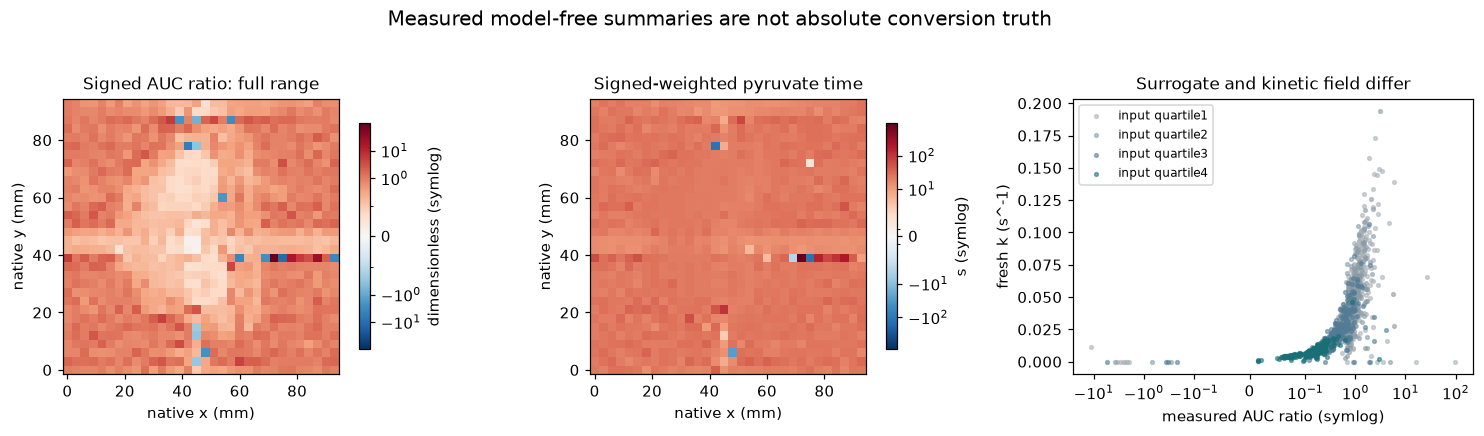

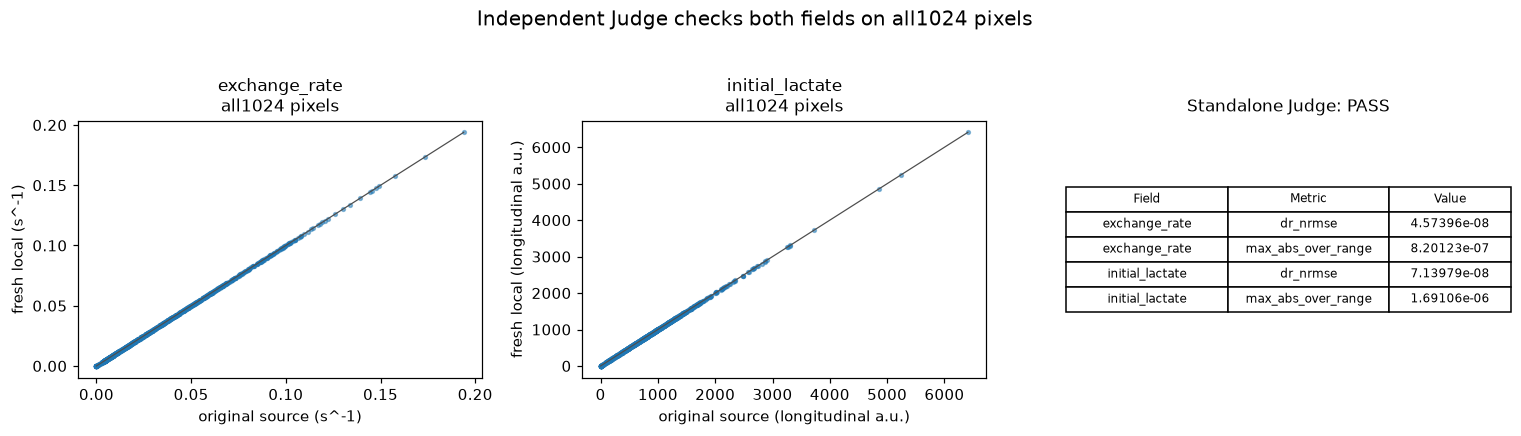

{
  "reconstruction_seconds": 28.823038399976213,
  "sensitivity_seconds": {
    "T1L20": 28.562922999990406,
    "T1L30": 28.53327280000667,
    "flip095": 28.698565200000303,
    "flip105": 26.943119400006253
  },
  "agreement": {
    "exchange_rate": {
      "ncc": 0.9999999999999819,
      "dr_nrmse": 4.573957748950697e-08,
      "max_abs_over_range": 8.201226081877829e-07
    },
    "initial_lactate": {
      "ncc": 0.9999999999999076,
      "dr_nrmse": 7.139788926671538e-08,
      "max_abs_over_range": 1.6910595211765337e-06
    }
  },
  "forward_null_labels": [
    "Zero signal",
    "Per-pixel constant",
    "k=0, fitted L0",
    "Fresh inputless"
  ],
  "forward_relative_l2": [
    1.0,
    0.5660148859024048,
    0.8332749565668754,
    0.489943916066924
  ],
  "negative_fitted_lactate_samples": 21,
  "negative_forcing_samples": 11161,
  "condition_range": [
    1.0069201886673118,
    2.4179172868738585
  ],
  "quartile_sensitivity_medians": [
    0.02368831972603345,
    0.

In [10]:
psum=signal[0].sum(-1,dtype=float);lsum=y.sum(-1,dtype=float);auc=lsum/psum;mean_time=np.sum(signal[0]*times,axis=-1)/psum
fig,ax=plt.subplots(1,3,figsize=(14,4))
im_auc=image(ax[0],auc,'Signed AUC ratio: full range','dimensionless (symlog)',signed=True);im_auc.set_norm(SymLogNorm(linthresh=.1,vmin=-abs(auc).max(),vmax=abs(auc).max()));im_auc.colorbar.set_ticks([-10,-1,0,1,10])
im_time=image(ax[1],mean_time,'Signed-weighted pyruvate time','s (symlog)',signed=True);im_time.set_norm(SymLogNorm(linthresh=5,vmin=-abs(mean_time).max(),vmax=abs(mean_time).max()));im_time.colorbar.set_ticks([-100,-10,0,10,100])
for i,col in enumerate(('#a9b1b7','#8a9ba6','#527c96','#186f76')):
    mask=quartile==i;ax[2].scatter(auc.ravel()[mask],k.ravel()[mask],s=6,alpha=.55,color=col,label=f'input quartile{i+1}')
ax[2].set_xscale('symlog',linthresh=.1);ax[2].set(xlabel='measured AUC ratio (symlog)',ylabel='fresh k (s^-1)',title='Surrogate and kinetic field differ');ax[2].legend(fontsize=8)
print('Signed-sum denominator range',psum.min(),psum.max(),'nonfinite AUC count',np.count_nonzero(~np.isfinite(auc)))
publish(fig,'12_auc_and_timing','Measured model-free summaries are not absolute conversion truth',auc_ratio=auc,mean_pyruvate_time=mean_time,pyruvate_sum=psum,lactate_sum=lsum,fresh_k=k,quartile=quartile.reshape(32,32))
cmd=[sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')]
completed=subprocess.run(cmd,cwd=ROOT,capture_output=True,text=True);report=json.loads((ROOT/'output/judge_report.json').read_text(encoding='utf8'));assert completed.returncode==0 and report['status']=='pass',report
fig,ax=plt.subplots(1,3,figsize=(14,4))
for a,key,unit in zip(ax[:2],('exchange_rate','initial_lactate'),('s^-1','longitudinal a.u.')):
    a.scatter(reference[key].ravel(),fresh[key].ravel(),s=6,alpha=.5);lo=0;hi=reference[key].max();a.plot([lo,hi],[lo,hi],color='.3',lw=.8);a.set(xlabel='original source ('+unit+')',ylabel='fresh local ('+unit+')',title=key+'\nall1024 pixels')
ax[2].axis('off');rows=[[key.split('/')[0],key.split('/')[1],f'{value:.6g}'] for key,value in report['metrics'].items() if key.endswith('dr_nrmse') or key.endswith('max_abs_over_range')];table=ax[2].table(cellText=rows,colLabels=['Field','Metric','Value'],loc='center',cellLoc='center',colWidths=[.4,.4,.3]);table.auto_set_font_size(False);table.set_fontsize(8);table.scale(1,1.8);ax[2].set_title('Standalone Judge: '+report['status'].upper())
publish(fig,'13_final_field_agreement','Independent Judge checks both fields on all1024 pixels',source_k=reference['exchange_rate'],source_L0=reference['initial_lactate'],fresh_k=fresh['exchange_rate'],fresh_L0=fresh['initial_lactate'])
summary={'reconstruction_seconds':reconstruction_seconds,'sensitivity_seconds':sensitivity_times,'agreement':agreement,'forward_null_labels':null_labels,'forward_relative_l2':null_values,'negative_fitted_lactate_samples':int(np.count_nonzero(pred<0)),'negative_forcing_samples':int(np.count_nonzero(diagnostics['forcing_signal_scaled']<0)),'condition_range':[float(condition.min()),float(condition.max())],'quartile_sensitivity_medians':sensitivity_medians.tolist(),'judge':report}
(ROOT/'notebooks/reference_outputs/fresh_summary.json').write_text(json.dumps(summary,indent=2,allow_nan=False),encoding='utf8');(FIG/'figure_manifest.json').write_text(json.dumps(exports,indent=2),encoding='utf8');print(json.dumps(summary,indent=2))

## 6. Conclusion

The actively reconstructed standard fields reproduce the original method on the same complete real observations and satisfy the independently frozen per-field numeric criteria. Full-data lactate residual is lower than zero, constant and zero-conversion/optimized-initial-state nulls. Analytic and continuous-time controls verify relaxation, exchange, RF depletion and temporal units.

The result is a **conditional method-reference**. Unknown relaxation and excitation calibration affect the maps, as the actual full-field refits demonstrate. Signed noisy pyruvate can imply negative interval forcing and fitted samples; these were preserved. Normalized full rank does not make weak-input background rates trustworthy, and the diagnostic sensitivity scale is not a confidence interval. There is no independent in-vivo conversion-rate truth, absolute mM calibration, anatomical registration or new claim about clinical cancer detection. The offered-data redistribution-rights limitation remains explicit.

Source numerical diagnostics, fresh outputs, prior source boundary failure and independent source-quality profiles remain separately labelled. All13 actual figure groups export PNG/SVG/PDF with paired numerical NPZ and JSON hashes in the private review archive.